--- ANALYSE ERGEBNIS --- 
Military: 0
Logistics: 2
Civilian/Other: 0
Unknown: 0


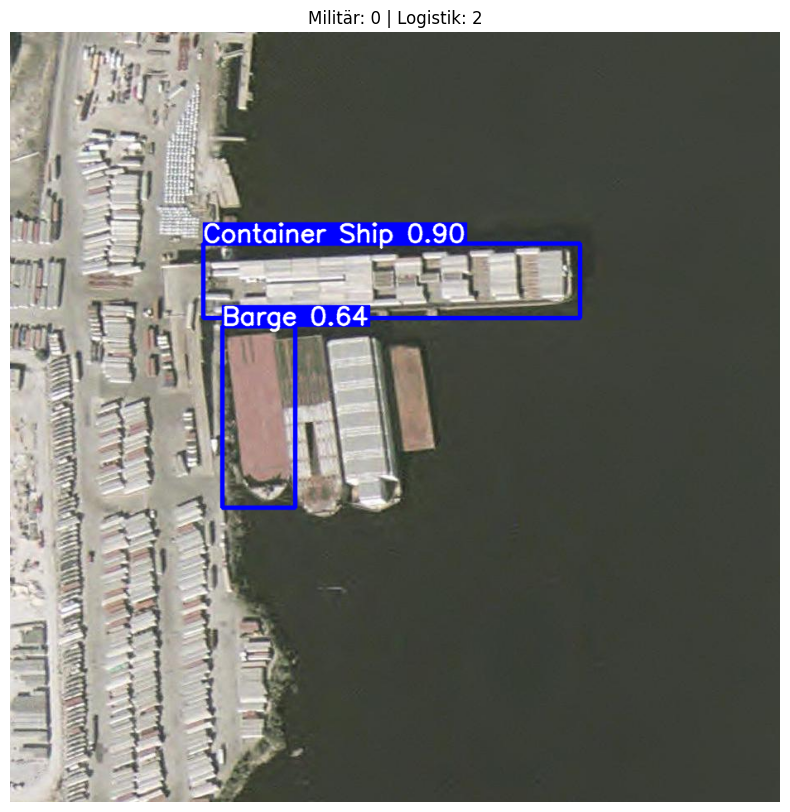

In [1]:
import sys
import os
import cv2
from ultralytics import YOLO
from ultralytics.utils.plotting import Annotator
import matplotlib.pyplot as plt

# Verbindung zu mapping.py herstellen
sys.path.append(os.path.abspath('..'))
from src.mapping import SHIP_MAPPING, CAT_COLORS

# Modell laden und Bildpfad angeben 
model = YOLO('../models/final_weights/best.pt')
test_img_path = '../data/processed/ship_data/test/images/000419_bmp.rf.6ff1d672e01955fb4fa0fe1e0ec902dd.jpg'

# Die KI rechnen lassen (Inference) 
results = model.predict(test_img_path, conf=0.4, iou=0.7, verbose=False)

# Das Ergebnis-Bild vorbereiten 
img = cv2.imread(test_img_path)
annotator = Annotator(img, line_width=3) 

# Liste um die Schiffe zu zählen
stats = {cat: 0 for cat in SHIP_MAPPING.keys()}
stats['Unknown'] = 0

# Die Ergebnisse der KI sortieren und die Schiffe zählen
for r in results:
    for box in r.boxes:
        cls_id = int(box.cls[0])
        label = model.names[cls_id]
        coords = box.xyxy[0]
        
        conf_val = float(box.conf[0]) 
        
        category = "Unknown"
        for cat, classes in SHIP_MAPPING.items():
            if label in classes:
                category = cat
                break
        
        stats[category] += 1
        
        
        current_color = CAT_COLORS.get(category, (128, 128, 128))
        annotator.box_label(coords, label=f"{label} {conf_val:.2f}", color=current_color)



# Alles anzeigen 
print(f"--- ANALYSE ERGEBNIS --- ")
for cat, count in stats.items():
    print(f"{cat}: {count}")

final_img = annotator.result()
img_rgb = cv2.cvtColor(final_img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 10))
plt.imshow(img_rgb)
plt.axis('off')
plt.title(f"Militär: {stats['Military']} | Logistik: {stats['Logistics']}")
plt.show()